<a href="https://colab.research.google.com/github/QuirozAlaniz/Regresion_lineal_categoricos/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [215]:
#Importamos las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from scipy import stats

In [216]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [217]:
#Carga de los datos
ruta = "/content/drive/MyDrive/UACJ/Programacion Desc Predict UACJ/20. Sesion 20/2. Datos Categoricos/college.csv"

In [218]:
df = pd.read_csv(ruta)
df.head()

,id,name,salary,cost,public,location
0,1,Massachusetts Institute of Technology (MIT),119000,189300,Private,NE
1,2,Harvard University,121000,189600,Private,NE
2,3,Dartmouth College,123000,188400,Private,NE
3,4,Princeton University,123000,188700,Private,NE
4,5,Yale University,110000,194200,Private,NE


In [219]:
print(df.info())
print(df[["salary", "cost"]].describe())
print("\nConteo por categorías de location:")
df["location"] = df["location"].astype("category")
print(df['location'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        85 non-null     int64 
 1   name      85 non-null     object
 2   salary    85 non-null     int64 
 3   cost      85 non-null     int64 
 4   public    85 non-null     object
 5   location  85 non-null     object
dtypes: int64(3), object(3)
memory usage: 4.1+ KB
None
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000

Conteo por categorías de location:
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




Text(0.5, 1.0, 'Histograma de distribución de salarios')

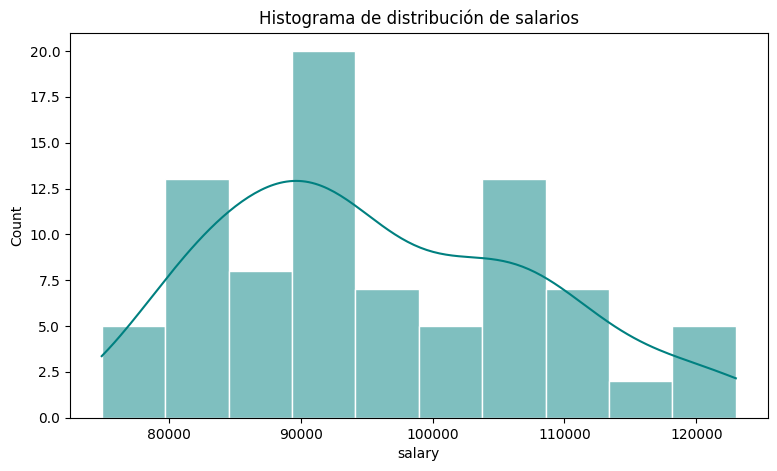

In [220]:
# 2. Graficar el histograma con la curva de densidad (KDE)
plt.figure(figsize=(9, 5))
sns.histplot(df["salary"], kde=True, color='teal', bins=10, edgecolor='white')
plt.title("Histograma de distribución de salarios")

La distribución del salario no se ajusta tanto a una distribución Normal, no es simétrica pues los datos están sesgados a la derecha, donde los salarios son más altos, pasando por los valores intermedios que muestran pocas frecuencias.
\
La mayor frecuencia de graduados se concentra en los rangos salariales bajos y medios (aproximadamente entre 80,000 y 95,000).
\
Los salarios más altos superan los 120,000

<Figure size 900x600 with 0 Axes>

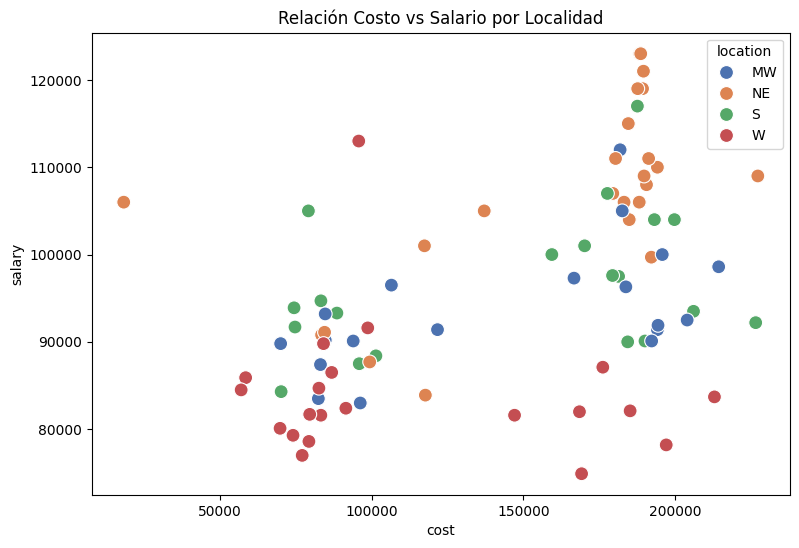

In [221]:
# Configuramos el tamaño del gráfico
plt.figure(figsize=(9, 6))

# Creamos el scatterplot con 4 colores basados en la variable categórica
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="cost", y="salary", hue="location", palette="deep", s=100)
plt.title("Relación Costo vs Salario por Localidad")
plt.show()

Se observa cierta tendencia que a mayor salario mayor el costo de la matrícula, principalmente en escuelas del Noreste mientras que las más baratas que tienen un salario menor son las del Oeste (West)

/tmp/ipykernel_3535/122071904.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(0.5, 1.0, 'Boxplot de costo por área geográfica')

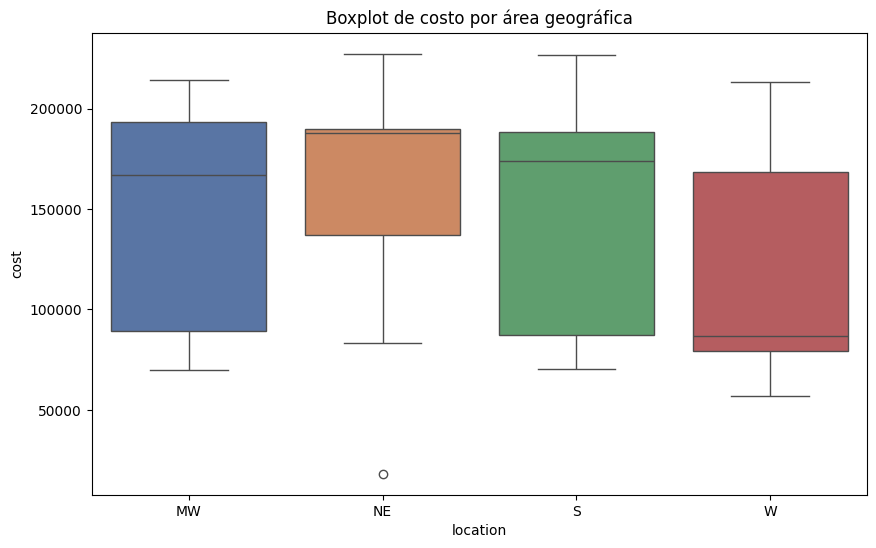

In [222]:
# Ajustamos el tamaño del cuadro
plt.figure(figsize=(10, 6))

# Creamos el boxplot
sns.boxplot(
    data=df,
    x="location",  # La variable con 4 categorías irá en el eje X
    y="cost",  # La variable numérica que quieres analizar (ej: salario o costo)
    palette="deep",  # Agrega colores estéticos automáticos
)
plt.title("Boxplot de costo por área geográfica")

Podemos observar que las escuelas del Noreste (NE) tienen los costos más elevados en general, aunque destaca la presencia de un outlier y datos más dispersos.
\
Las escuelas del Oeste (W) tienen los costos más bajos.
\
Claramente la localización geográfica influye fuertemente en el costo de la educación.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [223]:
print('Versión de One-hot encoding con Pandas: K')
df_codificado = pd.get_dummies(df, columns=['location'], drop_first = True)
print(df_codificado.head())
print('\n')
print('Debido a que las valores que asigna a cada columna son True/False')
print('Se realiza una conversión a 1/0 que indica la presencia/ausencia')
# Convertir valores booleanos a enteros
df_codificado = df_codificado.replace({True: 1, False:0})

print(df_codificado.head())

Versión de One-hot encoding con Pandas: K
   id                                         name  salary    cost   public  \
0   1  Massachusetts Institute of Technology (MIT)  119000  189300  Private   
1   2                           Harvard University  121000  189600  Private   
2   3                            Dartmouth College  123000  188400  Private   
3   4                         Princeton University  123000  188700  Private   
4   5                              Yale University  110000  194200  Private   

   location_NE  location_S  location_W  
0         True       False       False  
1         True       False       False  
2         True       False       False  
3         True       False       False  
4         True       False       False  


Debido a que las valores que asigna a cada columna son True/False
Se realiza una conversión a 1/0 que indica la presencia/ausencia
   id                                         name  salary    cost   public  \
0   1  Massachusetts Inst

/tmp/ipykernel_3535/763308892.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_codificado = df_codificado.replace({True: 1, False:0})


In [224]:
#Hacemos el modelo
X = df_codificado.drop(columns=["salary", "public", "name", "id"])  # Características
y = df['salary']  # Variable dependiente (ventas)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LinearRegression()
model.fit(X_scaled,y)

LinearRegression()

In [225]:
#Imprimir el intercepto y los coeficientes asociados a cada predictor
print(f"Intercepto (Beta 0): {model.intercept_:.4f}")
print("-" * 40)
for col, coef in zip(X.columns, model.coef_):
    print(f"Coeficiente para {col}: {coef:.4f}")

Intercepto (Beta 0): 95898.8235
----------------------------------------
Coeficiente para cost: 3243.4367
Coeficiente para location_NE: 5482.6953
Coeficiente para location_S: 1187.8574
Coeficiente para location_W: -3330.2581


In [226]:
coefficients = model.coef_
intercept = model.intercept_

print(f"\nCoeficientes estimados: {coefficients}")
print(f"Término independiente estimado: {intercept}")
#######################################################
print('\n')
equation = f"salario = {intercept} "
for i, coef in enumerate(coefficients):
  equation += f"+ ({coef} * {X.columns[i]}) "
equation #se obtiene el modelo con los coeficientes


Coeficientes estimados: [ 3243.43667632  5482.69532666  1187.85736252 -3330.25807951]
Término independiente estimado: 95898.82352941176




'salario = 95898.82352941176 + (3243.4366763169037 * cost) + (5482.695326658311 * location_NE) + (1187.8573625214553 * location_S) + (-3330.2580795070035 * location_W) '

Interpretación.
\
El término independiente o intercepto es el salario base, a partir de ese valor se le va a sumar o restar los montos de las demás variables.
\
El coeficiente de cost indica cuánto aumenta el salario predicho por cada unidad que incrementa el costo de la educación.
\
Por último, cada uno de los coeficientes de location_ indica cuánto aumenta o disminuye la suma de los dos conceptos anteriores dependiendo de en qué área geográfica se haya estudiado. Aquí funciona cuando una es 1, las demás toman el valor de 0.
\
Tener en cuenta que cuando el área geográfica sea la que no se ve (MW), el intercepto va a absorber los valores de la misma.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

In [227]:
#Normalidad de los residuos
y_pred = model.predict(X_scaled)
residuos = y - y_pred
print(residuos.head())

0    10522.494862
1    12504.339601
2    14576.960642
3    14558.805382
4     1225.958944
Name: salary, dtype: float64


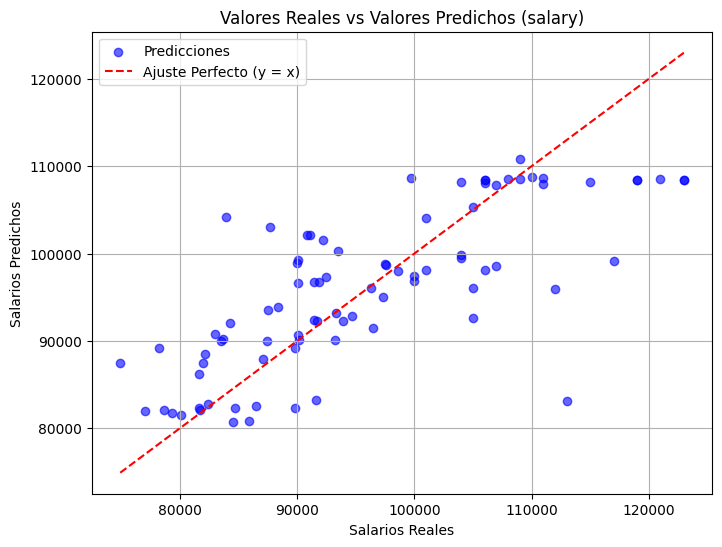

In [228]:
#Visualización de las Predicciones
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, alpha=0.6, color="blue", label="Predicciones")

# Línea de referencia ideal (donde y_real == y_pred)
min_val = min(min(y), min(y_pred))
max_val = max(max(y), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="Ajuste Perfecto (y = x)")

plt.xlabel("Salarios Reales")
plt.ylabel("Salarios Predichos")
plt.title("Valores Reales vs Valores Predichos (salary)")
plt.legend()
plt.grid(True)
plt.show()

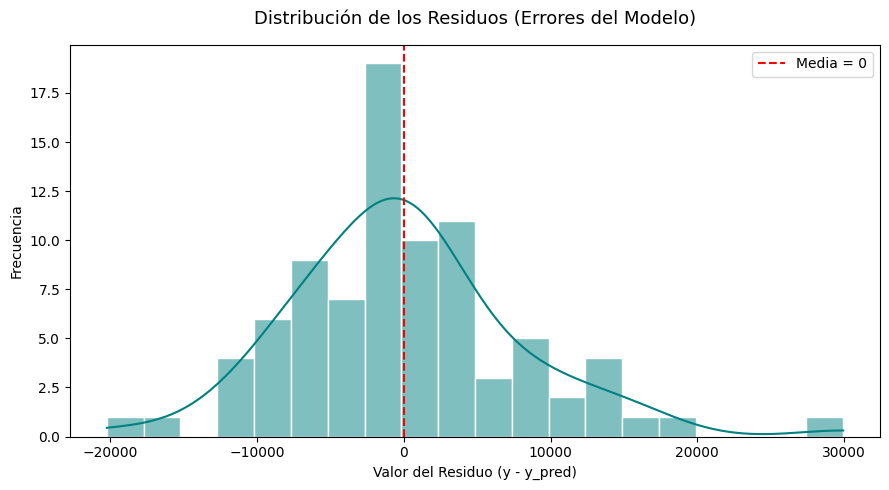

In [229]:
# 2. Graficar el histograma con la curva de densidad (KDE)
plt.figure(figsize=(9, 5))
sns.histplot(residuos, kde=True, color='teal', bins=20, edgecolor='white')

# Añadir elementos estéticos
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Media = 0')
plt.title('Distribución de los Residuos (Errores del Modelo)', fontsize=13, pad=15)
plt.xlabel('Valor del Residuo (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

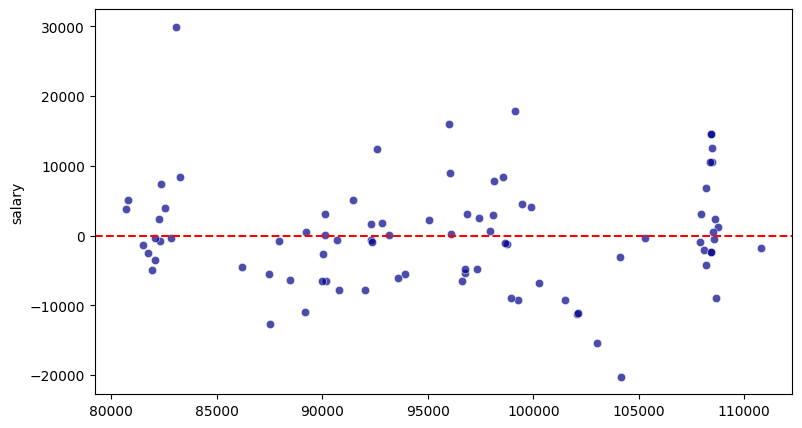

In [230]:
# Homocedasticidad
plt.figure(figsize=(9, 5))

# 1. Graficar la dispersión de predichos vs residuos
sns.scatterplot(x=y_pred, y=residuos, color='darkblue', alpha=0.7)

# Añadir una línea de referencia en Y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Residuo = 0')

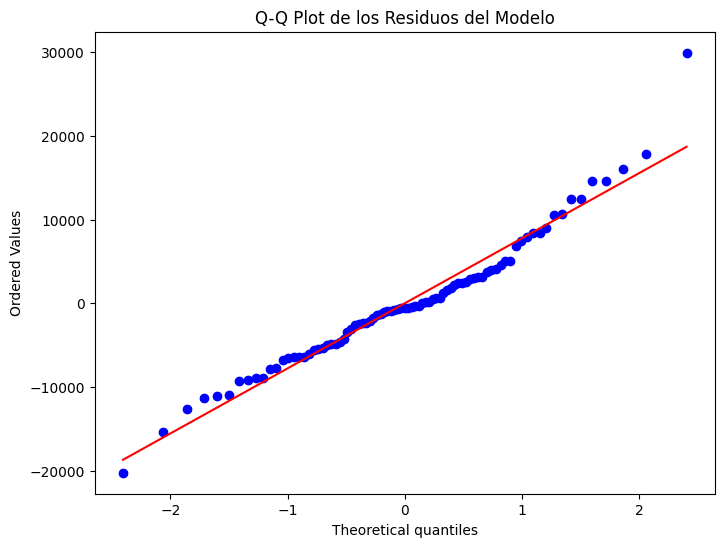

In [231]:
#Q-Q Plot
#. Graficar el Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)

# Añadir título
plt.title("Q-Q Plot de los Residuos del Modelo")

# Mostrar la gráfica
plt.show()

Podemos observar que los errores residuales se ajustan a una distribución estándar pero tiene datos que se salen de la curva, sobre todo en el centro, presencia de posibles outliers.
\
\
También podemos ver en la gráfica de los valores reales versus los valores predichos que no se ajustan tan bien, hay mucha variabilidad.
\
\
También vemos en la gráfica de homocedasticidad que los valores no siguen un patrón pero tampoco se ve que se distribuyan aleatoriamente de manera consistente, hay bastantes valores que se alejan del grupo principal. Esto indica que los erroes fallan o no se distribuyen de manera Normal como el modelo lo requiere.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [232]:
#Evaluación del Modelo
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 13. Calcular las métricas del modelo
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y, y_pred)  # Error absoluto medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2

# 14. Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

Error Cuadrático Medio (MSE): 60480269.1466
Raíz del Error Cuadrático Medio (RMSE): 7776.9061
Error Absoluto Medio (MAE): 5697.5542
Coeficiente de Determinación (R²): 0.5705


El coeficiente de determinación es 0.5705, lo cual nos indica que el 57.05% de la variabilidad se explica por las variables predictoras, lo cual es un nivel moderado. Esto quiere decir que hay otras variables que entran en juego pero que no estamos considerando, podría ser la carrera que se estudia por ejemplo.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [233]:
import statsmodels.api as sm
from statsmodels.regression.mixed_linear_model import VCSpec
from statsmodels.formula.api import ols

In [234]:
modelo_anova = ols('salary ~ cost + C(location)', data=df).fit() #Predecimos salary a partir de location. Las variables categóricas de location se convierten automáticamente
                                                                 # a código 0 ó 1

# Realizamos la tabla ANOVA
tabla_anova = sm.stats.anova_lm(modelo_anova, typ=2)
print(tabla_anova)

                   sum_sq    df          F        PR(>F)
C(location)  4.071774e+09   3.0  21.121259  3.570975e-10
cost         7.878166e+08   1.0  12.259774  7.600629e-04
Residual     5.140823e+09  80.0        NaN           NaN


Interpretación.
\
En la columna sum_sq odemos ver que el costo explica más la variación de la variable predecida que es salary, mientras que location explica casi la mita de lo que explica cost.
\
• PR(>F) nos dice la probabilidad de que el efecto observado se deba a la pura casualidad.
\
Si es menor a 0.05, la variable sí influye significativamente en el salario.
\
Como cost y location son mucho menores a 0.05, sí influyen significativamente en el salario.